In [22]:
!pip install pandas seaborn matplotlib
!pip install scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [23]:
!pip install -i https://pypi.tuna.tsinghua.edu.cn/simple "tensorflow" --force-reinstall

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/8f/a2/6d7e6a738e302530586d484895de2cf3fc158ad9c73b4504a670b2956dd9/tensorflow-2.21.0-cp311-cp311-win_amd64.whl (350.8 MB)
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/18/a6/907a406bb7d359e6a63f99c313846d9eec4f7e6f7437809e03aa00fa3074/absl_py-2.4.0-py3-none-any.whl (135 kB)
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/2b/03/13dde6512ad7b4557eb792fbcf0c653af6076b81e5941d36ec61f7ce6028/astunparse-1.6.3-py2.py3-none-any.whl (12 kB)
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/e8/2d/d2a548598be01649e2d46231d151a6c56d10b964d94043a335ae56ea2d92/flatbuffers-25.12.19-py2.py3-none-any.whl (26 kB)
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/1d/33/f1c6a276de27b7d7339a34749cc33fa87f077f921969c47185d34a887ae2/gast-0.7.0-py3-none-any.whl (22 kB)
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/a3/de/c648ef6835192e6e2cc03f4

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


1.1. Загрузите набор данных соответствующей цифре вашего варианта. Убедитесь, что загрузка прошла корректно.

In [24]:
#1.1
import pandas as pd 

df_lin = pd.read_csv('lab2_lin1.csv')
df_lin.head(5)

,Unnamed: 0,WorkingAges,LateTimes,KPI,Salary
0,0,20.0,21.0,4.37,3619.6
1,1,24.0,14.0,5.49,5333.7
2,2,22.0,14.0,3.53,3022.7
3,3,26.0,13.0,4.90,5079.7
4,4,18.0,20.0,5.75,4656.0


1.2. Используя train_test_split разбейте выборку на обучающую и тестовую. Проверьте, что тестовая выборка соответствует обучающей. Можно использовать диаграммы рассеяния/нормированные гистограммы/boxplot/violin plot.

Данные были распределены следующим образом: 15% тестовая выборка, 85% - обущающая, для это в методе train_test_split параметр test_size был инициализирован 0.15. Для оценки соответствия тестовой выборки обучающей была построена нормированная диаграмма. На представленных графиках видно, что тестовая выборка не полностью соответствует обучающей для обоих датасетов, это может помешать обучению, так как размер данных сильно изменить нельзя, можно выбрать другой random_state, при котором разница между данными будет минимальной.

Для наилучшего соответствия было проведено 10000 эксперементов для получения наименьшей разницы между средним значением и отклонением двух выборок, в итоге был вычеслен наилучший random_state, который был передан в метод traun_test_split. С таким распределением модель будет меньше ошибаться на тестовых данных, так как они максимально соответствуют обучающим.

In [43]:
#1.2

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

def preprocess(df):
    if 'Unnamed: 0' in df.columns:
        df = df.drop('Unnamed: 0', axis=1)
    
    train_dat, test_dat = train_test_split(df, test_size=0.15, random_state=42)
    
    print(f"Train: {len(train_dat)} ({len(train_dat)/len(df) * 100:.1f}%)")
    print(f"Test: {len(test_dat)} ({len(test_dat)/len(df) * 100:.1f}%)")

    n_features = len(df.columns)

    fig, axs = plt.subplots(1, n_features, figsize = (7 * n_features, 6))

    for idx, col in enumerate(df.columns):
        axs[idx].hist([train_dat[col].values, test_dat[col].values], density=True)
        axs[idx].set_ylabel(col)

    plt.legend(['Train', 'Test'])

    X_train = train_dat.iloc[:, :-1]
    y_train = train_dat.iloc[:, -1]
    X_test = test_dat.iloc[:, :-1]
    y_test = test_dat.iloc[:, -1]
    return df.iloc[:, :-1], df.iloc[:, -1], X_train, y_train, X_test, y_test



Train: 425 (85.0%)
Test: 75 (15.0%)


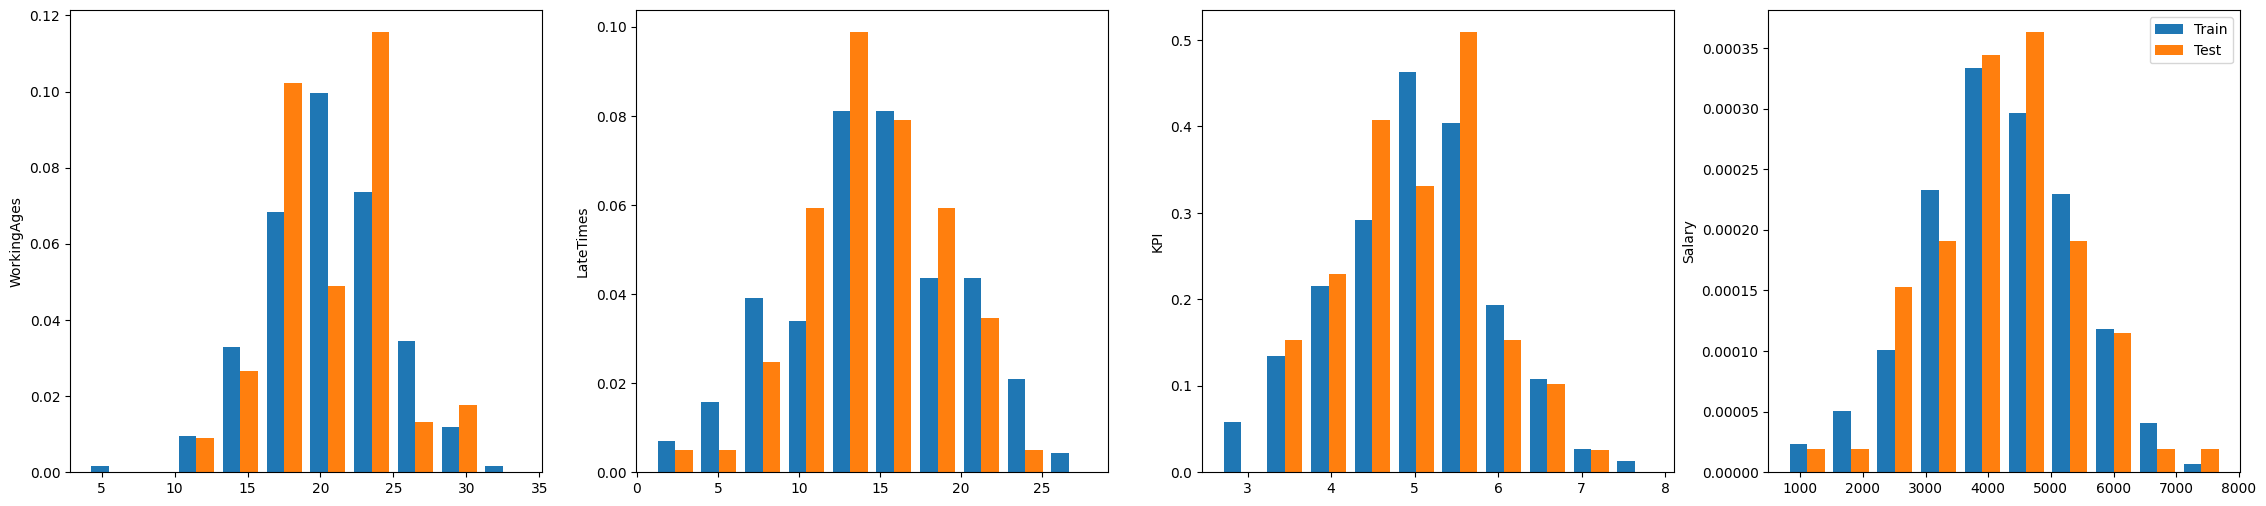

In [44]:
_, _, X_train_lin, y_train_lin, X_test_lin, y_test_lin = preprocess(df_lin)


1.3. Проведите линейную регрессию используя LinearRegression. Получите коэффициенты регрессии и объясните полученные результаты.

In [27]:
#1.3

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import  StandardScaler

def print_coef_lin_reg(model, col_name, reg_name):
    coef = model.coef_
    print('=' * 15, "Coefficient for", reg_name, '=' * 15)
    for feat, coef in zip(col_name, coef):
        print(f"  {feat:10s}: {coef:8.4f}")

scaler_x = StandardScaler()
X_train_norm = scaler_x.fit_transform(X_train_lin)
X_test_norm = scaler_x.transform(X_test_lin)

model_lin_reg = LinearRegression()
model_lin_reg.fit(X_train_norm, y_train_lin)

print_coef_lin_reg(model_lin_reg, X_test_lin.columns, "LinearRegression")


=============== Coefficient for LinearRegression ===============
  WorkingAges: 712.4704
  LateTimes :  -2.5063
  KPI       : 1001.1920


В качестве целевой переменной для датасета из файла lab2_lin1.csv был выбран крайний столбец - Salary. Был создан объект класса LinearRegression, для обучающей выборки была пострена линейная регрессия. По полученным коэффициентам можно сделать следующие выводы: Salary имеют положительную линейную зависимость от WorkingAges: при увеличеннии параметра WorkingAges на одну единицу, Salary возврастает на 172.3595 единиц;между параметрами Salary и LateTimes наблюдается слабая отрицательная зависимость: при уменьшении параметра LateTimes на одну единицу, Salary убывает на 0.1641 единиц; параметр KPI имеет наибольший коэффициент среди всех параметров: при возврастании KPI на 1 единицу, Salary возврастает на 1067.2937 единиц

1.4. Для обучающей и тестовой выборки рассчитайте коэффициент детерминации, MAPE, MAE. Объясните полученные значений метрик. Сравните метрики для обучающей и тестовой выборки, сделайте выводы о качестве обобщения полученной модели.

In [28]:
#1.4
from sklearn.metrics import r2_score, mean_absolute_error

def mape_score(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def metrics_for_reg(y_train, y_train_pred, y_test, y_test_pred, reg_name):
    results = {
        'Выборка': ['Train', 'Test'],
        'Коэффицент детерминации': [
            r2_score(y_train, y_train_pred), 
            r2_score(y_test, y_test_pred)
        ],
        'MAE': [
            mean_absolute_error(y_train, y_train_pred), 
            mean_absolute_error(y_test, y_test_pred)
        ],
        'MAPE': [
            mape_score(y_train, y_train_pred), 
            mape_score(y_test, y_test_pred)
        ]
    }

    print('=' * 15,"Metrics for", reg_name, '=' * 15)
    df_metrics = pd.DataFrame(results)
    print(df_metrics.to_string(index=False))


In [29]:
y_train_lin_pred = model_lin_reg.predict(X_train_norm)
y_test_lin_pred = model_lin_reg.predict(X_test_norm)
metrics_for_reg(y_train_lin, y_train_lin_pred, y_test_lin, y_test_lin_pred, "LinearRegresion")

=============== Metrics for LinearRegresion ===============
Выборка  Коэффицент детерминации       MAE     MAPE
  Train                 0.998302 42.359148 1.116762
   Test                 0.997955 46.417601 1.209297


Для обучающией и тестовой выборки были расчитаны коэффициент детерминации(функция r2_score(), на вход подаются реальное и предсказанное значение), MAE - среднее абсолютное отклонение каждого прогноза от соответствующего фактического значения(функция mean_absolute_error()) и MAPE - среднее абсолютное отклонение в процентах(MAPE = (1/n) × Σ |(Actual — Forecast) / Actual| × 10). Исходя из результатов построенная регрессионая модель имеет высокое качество на обоих наборах данных, что свидетельствует об отсутствии переобучения: коэффициент детерминации приблизительно равен 0,998 для обоих моделей, что подтверждает крайне сильную взаимосвязь между признаками (WorkingAges, LateTimes, KPI) и целевой переменной (Salary), значение MAPE не превышает 1,2% для обоих наборов данных, что указывает на высокую точность прогнозов и устойчивость модели к новым данным.

1.5. Повторите пункты 1.3 и 1.4 для модификаций линейной регрессии:
1.5.1. Лассо регрессия. Самостоятельно подберите гиперпараметры
1.5.2. Гребневая регрессия. Самостоятельно подберите гиперпараметры
1.5.3. ElasticNet. Самостоятельно подберите гиперпараметры

In [30]:
#1.5

from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

#Лассо регрессия
param_grid_lasso = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
}

lasso_search = GridSearchCV(
    Lasso(max_iter=10000), 
    param_grid_lasso,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
lasso_search.fit(X_train_norm, y_train_lin)

model_lasso_reg = lasso_search.best_estimator_
print_coef_lin_reg(model_lasso_reg, X_test_lin.columns, "LassoRegression")
y_train_lasso_pred = model_lasso_reg.predict(X_train_norm)
y_test_lasso_pred = model_lasso_reg.predict(X_test_norm)
metrics_for_reg(y_train_lin, y_train_lasso_pred, y_test_lin, y_test_lasso_pred, "LassoRegresion")
print('\n')

#Гребневая регрессия
param_grid_ridge = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0], 
    'solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sag']    
}

ridge_search = GridSearchCV(
    Ridge(random_state=42),
    param_grid_ridge,
    cv=5,                    
    scoring='r2',           
    n_jobs=-1               
)

ridge_search.fit(X_train_norm, y_train_lin)
model_ridge_reg = ridge_search.best_estimator_
print_coef_lin_reg(model_ridge_reg, X_test_lin.columns, "RidgeRegression")
y_train_ridge_pred = model_ridge_reg.predict(X_train_norm)
y_test_ridge_pred = model_ridge_reg.predict(X_test_norm)
metrics_for_reg(y_train_lin, y_train_ridge_pred, y_test_lin, y_test_ridge_pred, "RidgeRegresion")
print('\n')


#ElasticNet
param_grid_elastic = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0],     
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]  
}

elastic_search = GridSearchCV(
    ElasticNet(random_state=42, max_iter=10000),
    param_grid_elastic,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

elastic_search.fit(X_train_norm, y_train_lin)
model_elastic_reg = elastic_search.best_estimator_
print_coef_lin_reg(model_elastic_reg, X_test_lin.columns, "ElasticNetRegression")
y_train_elastic_pred = model_elastic_reg.predict(X_train_norm)
y_test_elastic_pred = model_elastic_reg.predict(X_test_norm)
metrics_for_reg(y_train_lin, y_train_elastic_pred, y_test_lin, y_test_elastic_pred, "ElasticNetRegresion")



=============== Coefficient for LassoRegression ===============
  WorkingAges: 712.3578
  LateTimes :  -2.4028
  KPI       : 1001.0918
=============== Metrics for LassoRegresion ===============
Выборка  Коэффицент детерминации       MAE     MAPE
  Train                 0.998302 42.360263 1.116594
   Test                 0.997957 46.404182 1.208802


=============== Coefficient for RidgeRegression ===============
  WorkingAges: 712.2911
  LateTimes :  -2.5046
  KPI       : 1000.9480
=============== Metrics for RidgeRegresion ===============
Выборка  Коэффицент детерминации       MAE     MAPE
  Train                 0.998302 42.363353 1.116477
   Test                 0.997955 46.432533 1.209441


=============== Coefficient for ElasticNetRegression ===============
  WorkingAges: 712.0886
  LateTimes :  -2.5020
  KPI       : 1000.6732
=============== Metrics for ElasticNetRegresion ===============
Выборка  Коэффицент детерминации       MAE     MAPE
  Train                 0.998302 42.3689

Для подбора параметров используется функция GridSearchCV для поиска лучшей модели. Описать виды регрессии.

1.6. Постройте сводную таблицу для рассчитываемых метрик, и используемых методов (с разделением на обучающую и тестовую выборку). По таблице сделайте выводы о том, какой вид регрессии дал лучшую модель. Опишите какие проблемы могут возникнуть при применении каждой модели. Для объяснения результатов можно построить “карту высот (heat map)” с отображением корреляции признаков.

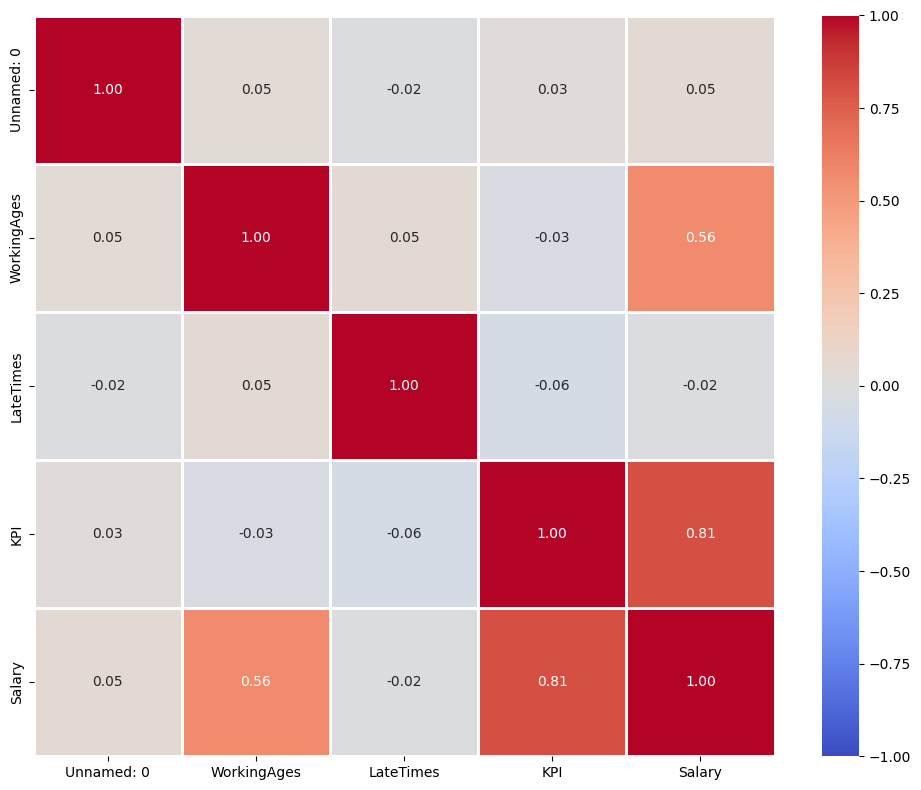

In [31]:
#1.6

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(10, 8))
correlation_matrix = df_lin.corr()
sns.heatmap(correlation_matrix, 
            annot=True,          
            cmap='coolwarm',     
            center=0,            
            square=True,        
            linewidths=1,     
            fmt=".2f",          
            vmin=-1, vmax=1)    
plt.tight_layout()
plt.show()

1.7. Для модели, которая дала лучшие результаты, постройте диаграмму рассеяния между предикторами и откликом. На диаграмме изобразите какое значение должно быть, и какое предсказывается. Визуально оцените качестве построенного регрессора.

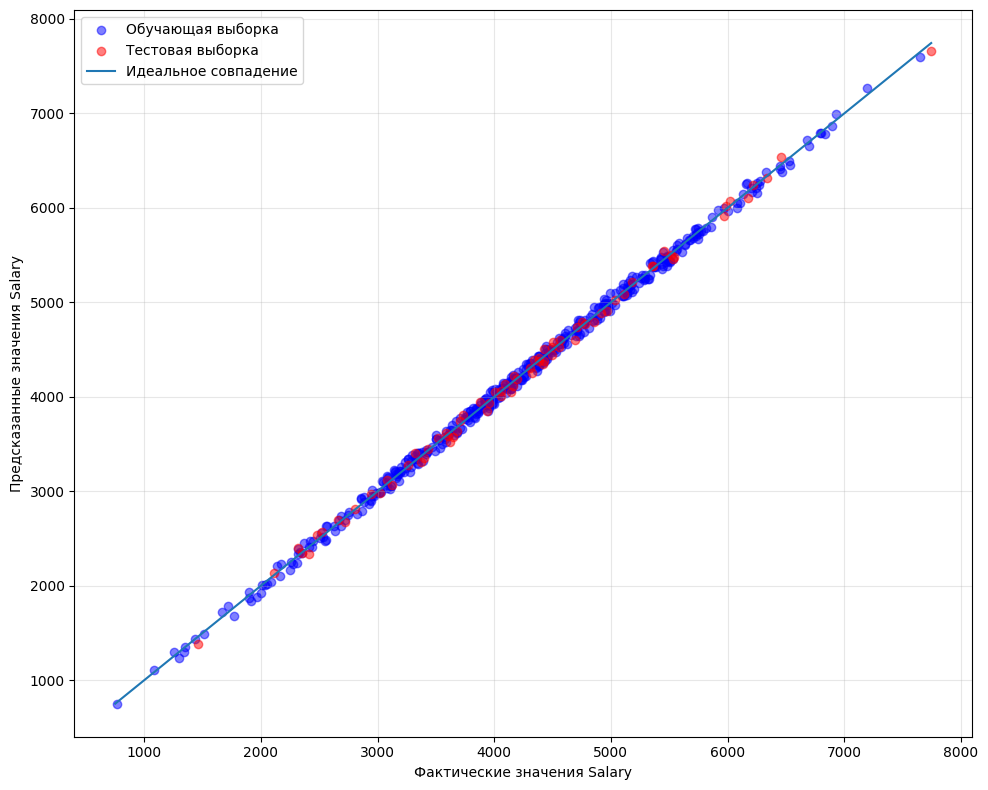

In [32]:
#1.7

import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

y_train_pred_ridge = model_lin_reg.predict(X_train_norm)
y_test_pred_ridge = model_lin_reg.predict(X_test_norm)

all_y_actual = np.concatenate([y_train_lin, y_test_lin])
all_y_predicted = np.concatenate([y_train_pred_ridge, y_test_pred_ridge])

plt.figure(figsize=(10, 8))

plt.scatter(y_train_lin, y_train_pred_ridge, 
            alpha=0.5, color='blue', label='Обучающая выборка')

plt.scatter(y_test_lin, y_test_pred_ridge, 
            alpha=0.5, color='red', label='Тестовая выборка')

min_val = min(all_y_actual.min(), all_y_predicted.min())
max_val = max(all_y_actual.max(), all_y_predicted.max())
plt.plot([min_val, max_val], [min_val, max_val],  label='Идеальное совпадение')

plt.xlabel('Фактические значения Salary')
plt.ylabel('Предсказанные значения Salary')

plt.legend(loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**2.Нелинейная регрессия**
2.1. Загрузите набор данных соответствующей букве вашего варианта. Убедитесь, что загрузка прошла корректно.

In [33]:
#2.1

df_poly = pd.read_csv('lab2_poly1.csv')
df_poly.head(5)

,Unnamed: 0,Age,Efficiency
0,0,5.454879,56.823834
1,1,29.075751,57.929242
2,2,1.612334,91.288050
3,3,11.212262,63.875004
4,4,43.043370,60.536451


2.2. Используя train_test_split разбейте выборку на обучающую и тестовую. Проверьте, что тестовая выборка соответствует обучающей.

Train: 425 (85.0%)
Test: 75 (15.0%)


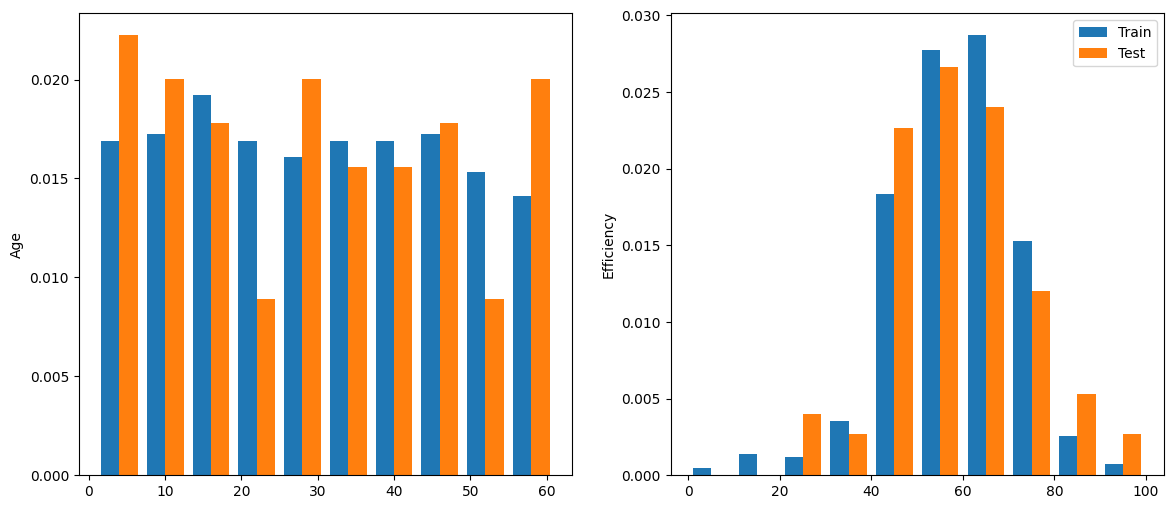

In [45]:
#2.2

X_poly, y_poly, X_train_poly, y_train_poly, X_test_poly, y_test_poly = preprocess(df_poly)


Для выполнения этого пункта использовалась функция, реализованная в пункте 1.2: для разбиения набора данных на обучающую и тестовую выборку подбирается значение random_state путем минимизации нормализованной разницы средних, для наилучшего соответствия выборок.

2.3. Проверьте работу стандартной линейной регрессии на загруженных данных. Постройте диаграмму рассеяния данных с выделенной полученной линией регрессии. Объясните полученный результат.

=============== Metrics for LinearRegression for polynomial data ===============
Выборка  Коэффицент детерминации       MAE      MAPE
  Train                 0.000531 10.416433 25.268547
   Test                -0.003955 11.642422 23.732684


C:\Users\katerina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


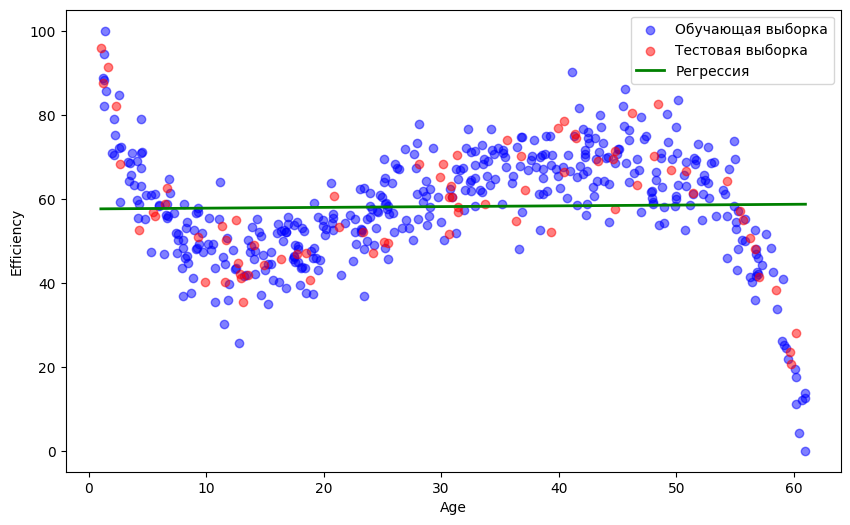

In [35]:
#2.3

lin_reg_for_poly = LinearRegression()
lin_reg_for_poly.fit(X_train_poly, y_train_poly)

y_train_pred = lin_reg_for_poly.predict(X_train_poly)
y_test_pred = lin_reg_for_poly.predict(X_test_poly)
metrics_for_reg(y_train_poly, y_train_pred, y_test_poly, y_test_pred, "LinearRegression for polynomial data")

plt.figure(figsize=(10, 6))
plt.scatter(X_train_poly, y_train_poly, alpha=0.5, color='blue', label='Обучающая выборка')
plt.scatter(X_test_poly, y_test_poly, alpha=0.5, color='red', label='Тестовая выборка')
plt.xlabel("Age")
plt.ylabel("Efficiency")

x_line = np.linspace(X_poly.min(), X_poly.max(), 100).reshape(-1, 1)
y_pred_line = lin_reg_for_poly.predict(x_line)
plt.plot(x_line, y_pred_line, 'g-', linewidth=2, label='Регрессия')
plt.legend()

Анализ диаграммы рассеяния показал, что зависимость между Age и Effectivity является существенно нелинейной с наличием нескольких локальных экстремумов. Стандартная линейная регрессия продемонстрировала крайне низкое качество аппроксимации, что так же подтверждает результат вычисления метрик(R2, MAE, MAPE)

2.4. Конструируя полиномиальный признаки для разных степеней полинома найдите степень полинома наилучшим образом аппроксимирующая данные. Постройте график зависимости коэффициента детерминации от степени полинома(на одном графике изобразите линии для обучающей и тестовой выборки отдельно). Сделайте вывод о том, при какой степени полинома модель начинает переобучаться.

best degree = 11


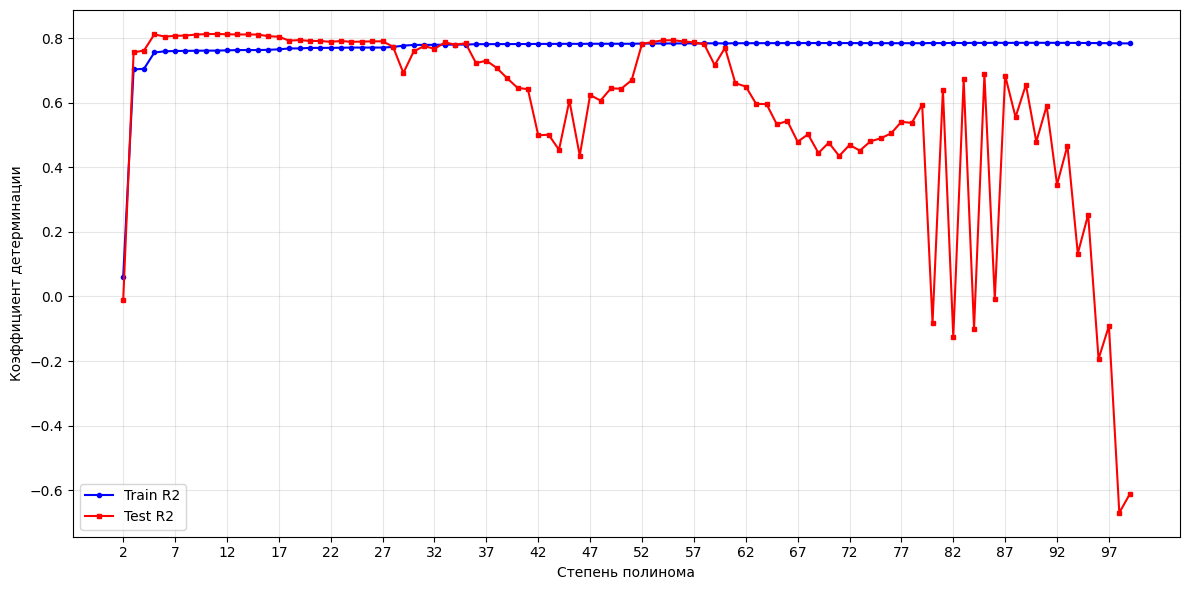

In [40]:
#2.4

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

degrees = range(2, 100)
r2_train_list = []
r2_test_list = []

scaler_x = RobustScaler()
X_train_norm = scaler_x.fit_transform(X_train_poly).astype(np.float64)
X_test_norm = scaler_x.transform(X_test_poly).astype(np.float64)

best_deg = 0
best_r2_train = 0
best_r2_test = 0
best_diff = 100

for deg in degrees:
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=deg)),
        ('linear', LinearRegression())
    ])

    model.fit(X_train_norm, y_train_poly)
    y_train_pred = model.predict(X_train_norm)  
    y_test_pred = model.predict(X_test_norm)

    r2_train = r2_score(y_train_poly, y_train_pred)
    r2_test = r2_score(y_test_poly, y_test_pred)
    diff = abs(r2_train - r2_test)

    r2_train_list.append(r2_train)
    r2_test_list.append(r2_test)

    if r2_train > best_r2_train and r2_test > best_r2_test:
        best_deg = deg
        best_r2_train = r2_train
        best_r2_test = r2_test
        best_diff = r2_test

print(f"best degree = {best_deg}")
import matplotlib.pyplot as plt

degrees = range(2, 100)

plt.figure(figsize=(12, 6))
plt.plot(degrees, r2_train_list, label='Train R2', color='blue', marker='o', markersize=3)
plt.plot(degrees, r2_test_list, label='Test R2', color='red', marker='s', markersize=3)

plt.xlabel('Степень полинома')
plt.ylabel('Коэффициент детерминации')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(degrees[::5]) 
plt.tight_layout()
plt.show()


Перед построением модели данные были нормализованы: без нормализации при высоких степенях(>10), на обучающей выборке метрики были хуже, хотя должно быть наоборот: полиномиальная регрессия на высоких степенях должна лучше описывать данные, на которых она обучалась, что собственно и должно приводить к переобучению. 

2.5. Для выбранной степени полинома, рассчитайте и проанализируйте полученные коэффициенты. Рассчитай значение метрик коэффициент детерминации, MAPE, MAE.

In [41]:
#2.5

from sklearn.pipeline import Pipeline

model = Pipeline([
    ('poly', PolynomialFeatures(degree=11)),
    ('linear', LinearRegression())
])

model.fit(X_train_norm, y_train_poly)
y_train_poly_pred = model.predict(X_train_norm)  
y_test_poly_pred = model.predict(X_test_norm)

coef_names = model.named_steps['poly'].get_feature_names_out(X_test_poly.columns)
final_coef = model.named_steps['linear'].coef_

print('=' * 15, "Coefficient for PolynomialRegression", '=' * 15)
for name, coef in zip(coef_names, final_coef):
    print(f"{name}: {coef:+8.9f}")

print('\n')
metrics_for_reg(y_train_poly, y_train_poly_pred, y_test_poly, y_test_poly_pred, "PolynomialRegresion")

=============== Coefficient for PolynomialRegression ===============
1: +0.000000000
Age: +28.821104579
Age^2: -26.709033792
Age^3: +1.920552576
Age^4: -15.706796326
Age^5: -106.743285959
Age^6: +275.631445985
Age^7: +54.188389182
Age^8: -441.514515580
Age^9: +89.404370535
Age^10: +218.874216295
Age^11: -98.813202121


=============== Metrics for PolynomialRegresion ===============
Выборка  Коэффицент детерминации      MAE      MAPE
  Train                 0.761369 5.212614 10.142418
   Test                 0.812989 5.138980  9.419957


2.6. Для выбранной степени полинома, постройте диаграмму рассеяния данных с линией соответствующей полученному полиному. Сделайте выводы о качестве аппроксимации.

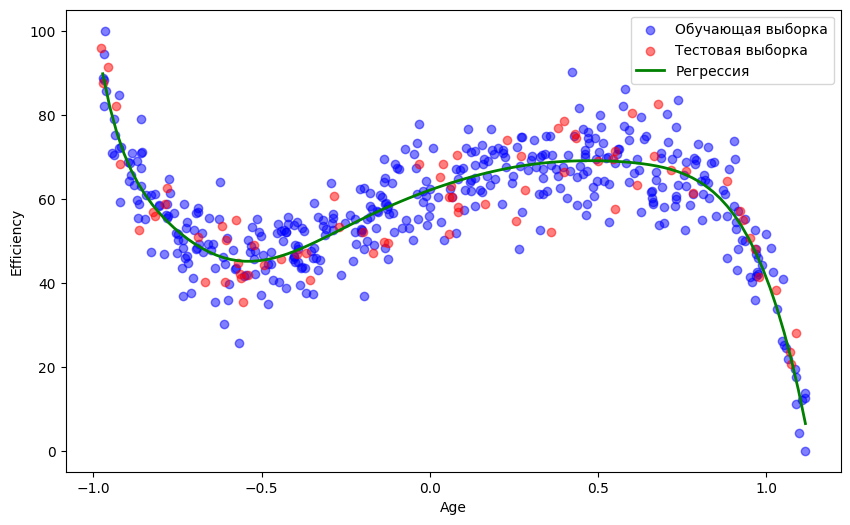

In [42]:
#2.6

plt.figure(figsize=(10, 6))
plt.scatter(X_train_norm, y_train_poly, alpha=0.5, color='blue', label='Обучающая выборка')
plt.scatter(X_test_norm, y_test_poly, alpha=0.5, color='red', label='Тестовая выборка')
plt.xlabel("Age")
plt.ylabel("Efficiency")

x_line = np.linspace(X_train_norm.min(), X_train_norm.max(), 100).reshape(-1, 1)
y_pred_line = model.predict(x_line)
plt.plot(x_line, y_pred_line, 'g-', linewidth=2, label='Регрессия')
plt.legend()

Оптимальное разделение выборок гарантирует хорошее соответствуие между ними: если регрессия соответствует обучающей выборке, то она будет соответствовать и тестовой. График полиномиальной регрессии 7 степени проходит через максимальные концентрации точек выборок, достаточно хорошо ее описывает.

2.7. Для выбранной степени полинома, решите задачу нелинейной регрессии без конструирования полиномиальных признаков и используя библиотеку TensorFlow.

In [39]:
#2.7

import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler

X_test_poly_tf = tf.constant(X_test_norm, dtype = tf.float64)
X_train_poly_tf = tf.constant(X_train_norm, dtype = tf.float64)
y_train_poly_tf = tf.constant(y_train_poly.to_numpy().reshape(-1, 1), dtype=tf.float64)

epoch_n = 20000
degree = 11
names = [f'coef_{i}' for i in range(degree + 1)]
coefs = [tf.Variable(0.0, dtype=tf.float64, name=sym) for sym in names]

optimizer = tf.keras.optimizers.SGD(learning_rate=0.001) 
for epoch in range(epoch_n):
    with tf.GradientTape() as tape:
        y_train_pred_tf = tf.math.polyval(coefs, X_train_poly_tf)
        loss = tf.reduce_mean(tf.square(y_train_poly_tf - y_train_pred_tf))
        
    grads = tape.gradient(loss, coefs)
    optimizer.apply_gradients(zip(grads, coefs))
    if(epoch + 1) % 1000 == 0:
        print(f"Epoch: {epoch+1}, Loss: {loss.numpy()}")


KeyboardInterrupt: 

2.8. Рассчитай метрики коэффициент детерминации, MAPE, MAE, а также постройте диаграмму рассеяния для данных линией соответствующей полученному полиному, для модели полученной при помощи TensorFlow.

=============== Metrics for PolynomialRegression by TenzorFlow ===============
Выборка  Коэффицент детерминации      MAE      MAPE
  Train                 0.758955 5.547031 10.959739
   Test                 0.571498 5.471337  9.748029


C:\Users\katerina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


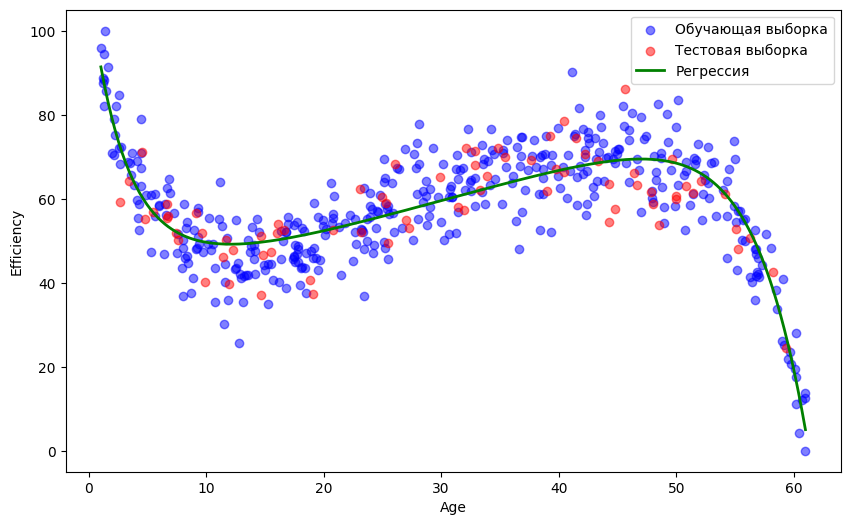

In [19]:
#2.8

X_test_poly_tf = tf.constant(X_test_norm, dtype = tf.float64)

y_train_pred = tf.math.polyval(coefs, X_train_poly_tf).numpy().ravel()
y_test_pred = tf.math.polyval(coefs, X_test_poly_tf).numpy().ravel()

metrics_for_reg(y_train_poly, y_train_pred, y_test_poly, y_test_pred, "PolynomialRegression by TenzorFlow")

plt.figure(figsize=(10, 6))
plt.scatter(X_train_poly, y_train_poly, alpha=0.5, color='blue', label='Обучающая выборка')
plt.scatter(X_test_poly, y_test_poly, alpha=0.5, color='red', label='Тестовая выборка')
plt.xlabel("Age")
plt.ylabel("Efficiency")

x_line = np.linspace(X_train_poly.min(), X_train_poly.max(), 200).reshape(-1, 1)
x_line_scaled = scaler_x.transform(x_line).astype(np.float64)
x_line_tensor = tf.constant(x_line_scaled, dtype=tf.float64)
y_pred_line = tf.math.polyval(coefs, x_line_tensor).numpy().ravel()
plt.plot(x_line.flatten(), y_pred_line, 'g-', linewidth=2, label='Регрессия')
plt.legend()